# 01 · Análisis exploratorio (EDA)

**Pregunta de negocio (hipotética):** una entidad pública que diseña programas de formalización
laboral y protección a la vejez quiere identificar qué trabajadores tienen alta probabilidad de
**no cotizar a pensión** (informalidad), para focalizar campañas y subsidios.

- **Fuente:** Gran Encuesta Integrada de Hogares (GEIH) – DANE, 10 meses (ene–abr 2024, ene–abr 2025, ene–feb 2026).
- **Unidad:** un trabajador ocupado.
- **Variable objetivo:** `INFORMAL = 1` si no cotiza a pensión (`COTIZA_PENSION == 2`), `0` si cotiza.

Este notebook busca entender los datos y definir la estrategia de preprocesamiento.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from informalidad.config import use_project_root
use_project_root()  # rutas relativas desde la raíz del proyecto

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#2a6fbb", "#e07b39", "#8a94a6"
pd.set_option("display.float_format", "{:,.4f}".format)

In [2]:
from informalidad.data import default_data_path, load_dataset

path = default_data_path()   # dataset completo si existe; si no, la muestra de data/sample
df = load_dataset(path)
print(f"Archivo: {path.name}  ->  {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head()

Archivo: geih_informalidad_10meses.csv  ->  287,900 filas x 15 columnas


,SEXO,EDAD,NIVEL_EDUCATIVO,ESTADO_CIVIL,DEPARTAMENTO,AFILIADO_SALUD,POSICION_OCUPACIONAL,TIENE_CONTRATO,INGRESO_MONETARIO,HORAS_SEMANA,COTIZA_PENSION,INGRESO_LABORAL,RAMA_ACTIVIDAD,MES_PERIODO,INFORMAL
0,2,32,5,2,5,1,1,1,"1,160,000.0000",47,1,"1,160,000.0000",14,Enero 2024,0
1,1,39,4,2,5,1,1,1,"1,600,000.0000",47,1,"1,600,000.0000",41,Enero 2024,0
2,1,22,4,6,5,2,1,1,"1,500,000.0000",47,2,"1,500,000.0000",41,Enero 2024,1
3,1,37,10,6,5,1,1,1,0.0000,48,1,"1,160,000.0000",47,Enero 2024,0
4,1,41,4,2,5,1,1,1,"1,300,000.0000",48,1,"1,300,000.0000",41,Enero 2024,0


## 1. Calidad de datos

In [3]:
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_unicos": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
resumen

,tipo,nulos,valores_unicos,min,max
AFILIADO_SALUD,int64,0,3,1.0000,9.0000
COTIZA_PENSION,int64,0,2,1.0000,2.0000
DEPARTAMENTO,int64,0,33,5.0000,99.0000
EDAD,int64,0,84,15.0000,100.0000
ESTADO_CIVIL,int64,0,6,1.0000,6.0000
HORAS_SEMANA,int64,0,116,1.0000,130.0000
INFORMAL,int64,0,2,0.0000,1.0000
INGRESO_LABORAL,float64,0,4038,0.0000,"103,000,000.0000"
INGRESO_MONETARIO,float64,0,2696,0.0000,"100,000,000.0000"
MES_PERIODO,str,0,10,NaN,NaN


In [4]:
tasa = df["INFORMAL"].mean()
print(f"Tasa de informalidad: {tasa:.1%}  (clases razonablemente balanceadas)")
df["INFORMAL"].value_counts().rename({0: "Formal", 1: "Informal"})

Tasa de informalidad: 56.9%  (clases razonablemente balanceadas)


INFORMAL
Informal    163940
Formal      123960
Name: count, dtype: int64

**Hallazgos de calidad**

- No hay nulos. El dataset lo genera `scripts/build_dataset.py` a partir de los CSV crudos de la GEIH
  (une *Características generales* con *Ocupados* y hace una imputación mínima del ingreso con la
  mediana del mismo mes).
- Los códigos categóricos se guardan como enteros; la validación igual revisa tipos y dominios.
- `NIVEL_EDUCATIVO` es la variable **P3042** de la GEIH (*mayor nivel educativo alcanzado*, 13 niveles
  + 99 "no sabe"). **Corrección frente al proyecto anterior:** allí se había tomado P6083 como nivel
  educativo, pero en el diccionario del DANE P6083 es *"¿La madre de ... reside en este hogar?"*
  (1 Sí, 2 No, 3 Fallecida). Al reconstruir el dataset desde los datos crudos, todas las demás
  columnas coinciden con las del proyecto anterior.

## 2. Informalidad por grupos

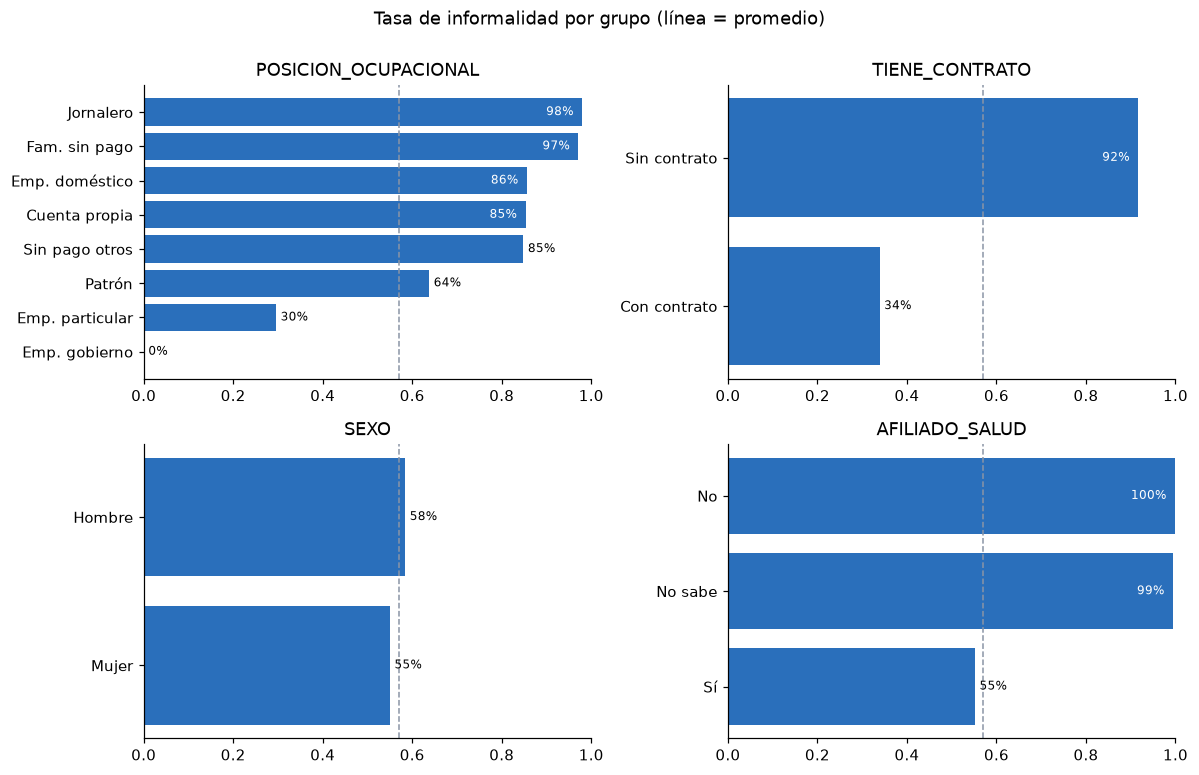

In [5]:
etiquetas = {
    "POSICION_OCUPACIONAL": {1: "Emp. particular", 2: "Emp. gobierno", 3: "Emp. doméstico",
                             4: "Cuenta propia", 5: "Patrón", 6: "Fam. sin pago",
                             7: "Sin pago otros", 8: "Jornalero"},
    "TIENE_CONTRATO": {1: "Con contrato", 2: "Sin contrato"},
    "SEXO": {1: "Hombre", 2: "Mujer"},
    "AFILIADO_SALUD": {1: "Sí", 2: "No", 9: "No sabe"},
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, mapa) in zip(axes.ravel(), etiquetas.items()):
    t = df.groupby(col)["INFORMAL"].agg(["mean", "size"]).rename(index=mapa).sort_values("mean")
    ax.barh(t.index.astype(str), t["mean"], color=AZUL)
    ax.axvline(tasa, color=GRIS, ls="--", lw=1)
    ax.set_title(col)
    ax.set_xlim(0, 1)
    for y, v in enumerate(t["mean"]):
        dentro = v > 0.85
        ax.text(v - 0.02 if dentro else v + 0.01, y, f"{v:.0%}", va="center", fontsize=8,
                ha="right" if dentro else "left", color="white" if dentro else "black")
fig.suptitle("Tasa de informalidad por grupo (línea = promedio)", y=1.0)
fig.tight_layout()

- **Posición ocupacional** separa casi perfectamente algunos grupos: empleados del gobierno ≈ 0 %,
  cuenta propia ≈ 85 %, jornaleros ≈ 98 %.
- **Contrato** es muy informativo (34 % vs 92 %). Ojo: está muy ligado a la definición de
  formalidad, así que el modelo es "fácil" en esos segmentos; el valor está en los casos intermedios
  (p. ej. empleados particulares, donde la informalidad es ≈ 30 %).

,tasa,n
NIVEL_EDUCATIVO,,
Ninguno,0.9580,7526
Preescolar,1.0000,19
Primaria,0.8750,49742
Secundaria,0.8329,30703
Media académica,0.6244,91047
Media técnica,0.5269,7216
Normalista,0.4407,413
Técnica prof.,0.3744,26378
Tecnológica,0.3042,12051


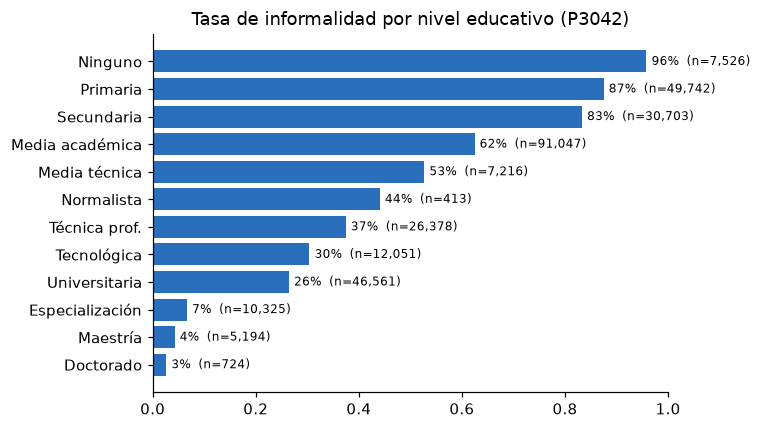

In [6]:
niveles = {1: "Ninguno", 2: "Preescolar", 3: "Primaria", 4: "Secundaria", 5: "Media académica",
           6: "Media técnica", 7: "Normalista", 8: "Técnica prof.", 9: "Tecnológica",
           10: "Universitaria", 11: "Especialización", 12: "Maestría", 13: "Doctorado", 99: "No sabe"}
edu = (df.groupby("NIVEL_EDUCATIVO")["INFORMAL"].agg(tasa="mean", n="size")
         .rename(index=niveles))
fig, ax = plt.subplots(figsize=(7, 4))
t = edu[edu["n"] >= 100].iloc[::-1]          # se omiten niveles con muy pocos casos
ax.barh(t.index, t["tasa"], color=AZUL)
ax.set_xlim(0, 1); ax.set_title("Tasa de informalidad por nivel educativo (P3042)")
for i, (v, n) in enumerate(zip(t["tasa"], t["n"])):
    ax.text(v + 0.01, i, f"{v:.0%}  (n={n:,})", va="center", fontsize=8)
fig.tight_layout()
edu

- **Nivel educativo** muestra un gradiente muy marcado: la informalidad pasa de ≈ 96 % sin
  educación y ≈ 88 % con primaria, a ≈ 62 % con bachillerato, ≈ 26 % con universitaria y menos de 7 %
  con posgrado. Es una variable clave que el modelo anterior no tenía (usaba P6083 por error).
- *Preescolar* (19 casos) y *No sabe* (1 caso) son muy raros: el `OneHotEncoder` con `min_frequency`
  los agrupa como categoría "infrecuente", así que no generan columnas inestables.

## 3. Variables numéricas

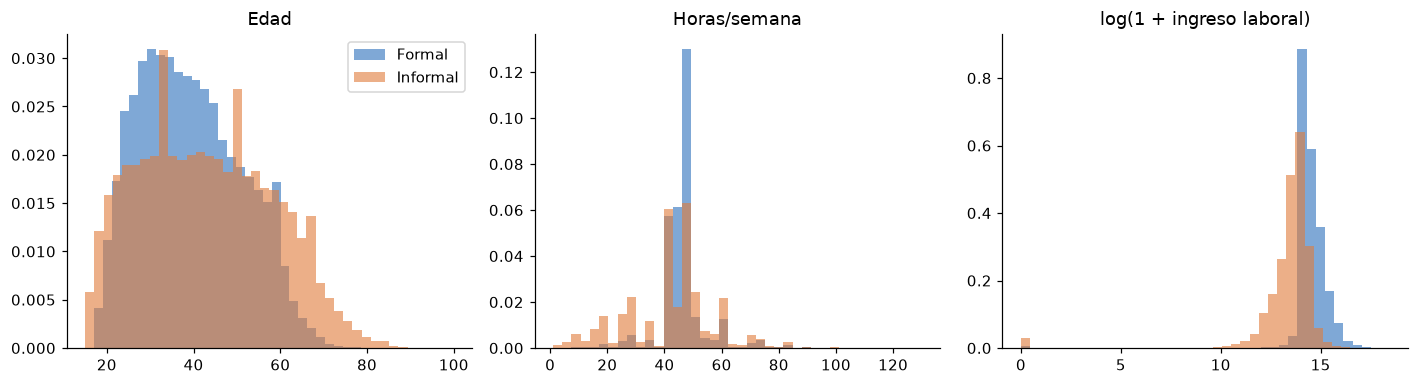

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, transform, titulo) in zip(axes, [
    ("EDAD", lambda s: s, "Edad"),
    ("HORAS_SEMANA", lambda s: s, "Horas/semana"),
    ("INGRESO_LABORAL", np.log1p, "log(1 + ingreso laboral)"),
]):
    for y, color, nombre in [(0, AZUL, "Formal"), (1, NARANJA, "Informal")]:
        ax.hist(transform(df.loc[df.INFORMAL == y, col]), bins=40, alpha=0.6,
                color=color, label=nombre, density=True)
    ax.set_title(titulo)
axes[0].legend()
fig.tight_layout()

In [8]:
print("Asimetría del ingreso:", round(df["INGRESO_LABORAL"].skew(), 2), "-> se usa log(1 + x)")
df.groupby("INFORMAL")[["EDAD", "HORAS_SEMANA", "INGRESO_LABORAL"]].median()

Asimetría del ingreso: 12.15 -> se usa log(1 + x)


,EDAD,HORAS_SEMANA,INGRESO_LABORAL
INFORMAL,,,
0,38.0000,47.0000,"1,750,905.0000"
1,42.0000,44.0000,"900,000.0000"


## 4. Estabilidad en el tiempo (clave para MLOps)

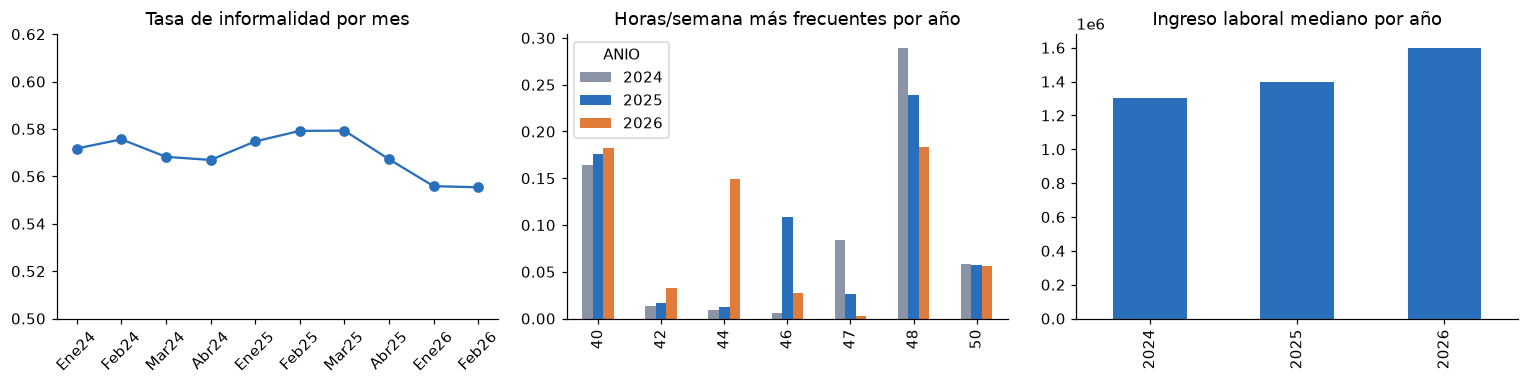

In [9]:
orden = ["Enero 2024", "Febrero 2024", "Marzo 2024", "Abril 2024",
         "Enero 2025", "Febrero 2025", "Marzo 2025", "Abril 2025",
         "Enero 2026", "Febrero 2026"]
por_mes = df.groupby("MES_PERIODO")["INFORMAL"].mean().reindex(orden)

df["ANIO"] = df["MES_PERIODO"].str.split().str[1]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(range(len(orden)), por_mes.values, marker="o", color=AZUL)
axes[0].set_xticks(range(len(orden)), [m[:3] + m[-2:] for m in orden], rotation=45)
axes[0].set_ylim(0.5, 0.62); axes[0].set_title("Tasa de informalidad por mes")

horas = df.groupby("ANIO")["HORAS_SEMANA"].value_counts(normalize=True).unstack(0)
horas.loc[[40, 42, 44, 46, 47, 48, 50]].plot.bar(ax=axes[1], color=[GRIS, AZUL, NARANJA])
axes[1].set_title("Horas/semana más frecuentes por año"); axes[1].set_xlabel("")

df.groupby("ANIO")["INGRESO_LABORAL"].median().plot.bar(ax=axes[2], color=AZUL)
axes[2].set_title("Ingreso laboral mediano por año"); axes[2].set_xlabel("")
fig.tight_layout()

- La **tasa de informalidad es estable** (55–58 %): no hay *concept drift* evidente en el objetivo.
- Pero **las variables de entrada sí cambian**:
  - Las horas típicas pasan de 48 → 47 → 46 → 44, en línea con la reducción gradual de la jornada
    laboral (Ley 2101 de 2021).
  - El ingreso nominal sube cada año (la moda pasa de $1.300.000 a $1.423.500, el salario mínimo de
    cada año).
- Por esto: (1) el modelo se evalúa con un **test fuera de tiempo** (ene–feb 2026) y no con un
  split aleatorio; (2) el **monitoreo con PSI** vigila justamente estas variables.

## 5. Estrategia de preprocesamiento (decisiones)

| Decisión | Por qué |
|---|---|
| Excluir `COTIZA_PENSION` | Define el target → data leakage |
| Excluir `INGRESO_MONETARIO` | Redundante con `INGRESO_LABORAL` (corr. 0.67) |
| `DEPARTAMENTO` solo para monitoreo | Evita 33 dummies; se usa para segmentar el monitoreo |
| `log(1+ingreso)` y `log(1+ingreso por hora)` | Asimetría muy alta (12) y separa "pocas horas" de "poco por hora" |
| One-hot de códigos categóricos (con categoría "infrecuente") | Son códigos, no cantidades; protege ante códigos nuevos |
| Todo dentro de un `sklearn.Pipeline` | El mismo objeto se entrena y se despliega (sin *training-serving skew*) |
| Split temporal: test = ene–feb 2026 | Simula producción: predecir meses que el modelo no vio |